# Prediction Quantum Benchmark

Run the existing benchmark pipeline from Jupyter without copying its implementation. The benchmark compares a variational quantum classifier with classical baselines on the Avatar EEG recordings.

## Before you start

- Select a Python environment for this project and install the packages from [`requirements.txt`](requirements.txt) into that same environment. This notebook does not install packages automatically. The benchmark requires PennyLane; a missing dependency in the selected Jupyter kernel will prevent it from starting.
- Make sure the repository's `Data_clean/` directory is present, or change `DATA_DIR` in the settings cell below.
- The quick smoke run uses a small budget and writes to `results_quick/`. Set `QUICK_RUN = False` for the full benchmark, which uses the settings in `configs/default.yaml` and may take a long time on CPU.
- Completed runs are reused by the benchmark, so you can rerun the full benchmark after an interruption. Set `FORCE = True` only when you want to redo completed runs.

Run the cells from top to bottom.

In [1]:
from pathlib import Path


cwd = Path.cwd().resolve()
candidates = [cwd, cwd / "prediction-quantum"]
candidates.extend(cwd.parents)
PROJECT_DIR = next(
    (path for path in candidates if (path / "prediction_quantum" / "run_benchmark.py").is_file()),
    None,
)
if PROJECT_DIR is None:
    raise FileNotFoundError(
        "Could not find prediction-quantum. Open this notebook from the project directory "
        "or its repository root."
    )

REPO_ROOT = PROJECT_DIR.parent
print(f"Project: {PROJECT_DIR}")
print(f"Repository: {REPO_ROOT}")

Project: /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum
Repository: /home/prasndhdl/Downloads/avatar/Tellekynezix


In [2]:
# Edit these options before running the benchmark.
DATA_DIR = REPO_ROOT / "Data_clean"
QUICK_RUN = False
N_JOBS = 2
FORCE = False

DATA_DIR = Path(DATA_DIR).expanduser().resolve()
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"EEG data directory not found: {DATA_DIR}. Set DATA_DIR to the Data_clean directory."
    )
if not isinstance(N_JOBS, int) or N_JOBS < 1:
    raise ValueError("N_JOBS must be a positive integer.")

CONFIG_PATH = PROJECT_DIR / "configs" / "default.yaml"
if not CONFIG_PATH.is_file():
    raise FileNotFoundError(f"Benchmark config not found: {CONFIG_PATH}")

OUTPUT_DIR = PROJECT_DIR / ("results_quick" if QUICK_RUN else "results")
REPORT_PATH = OUTPUT_DIR / "BENCHMARK_quick.md" if QUICK_RUN else PROJECT_DIR / "BENCHMARK.md"
print(f"Data: {DATA_DIR}")
print(f"Mode: {'quick smoke run' if QUICK_RUN else 'full benchmark'}")
print(f"Output: {OUTPUT_DIR}")

Data: /home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean
Mode: full benchmark
Output: /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/results


In [3]:
import subprocess
import sys


command = [
    sys.executable,
    "-m",
    "prediction_quantum.run_benchmark",
    "--config",
    str(CONFIG_PATH),
    "--data-dir",
    str(DATA_DIR),
    "--n-jobs",
    str(N_JOBS),
]
if QUICK_RUN:
    command.append("--quick")
if FORCE:
    command.append("--force")

print("Running:", " ".join(command))
subprocess.run(command, cwd=PROJECT_DIR, check=True)

Running: /home/prasndhdl/ai_env/bin/python -m prediction_quantum.run_benchmark --config /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/configs/default.yaml --data-dir /home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean --n-jobs 2
[20:53:07] config /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/configs/default.yaml -> /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/results


/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator PCA from version 1.9.1 when using version 1.9.0. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(
/home/prasndhdl/ai_env/lib/python3.12/site-packages/sklearn/base.py:525: InconsistentVersionWarning: Trying to unpickle estimator StandardScaler from version 1.9.1 when using version 1.9.0. This might 

[20:53:07] data: 11698 windows of 883 recordings used; chance level 0.171
[20:53:07] training: 0 of 60 runs to do in 2 processes x 2 threads
[20:53:08] done: 60 runs, report /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/BENCHMARK.md, 0.3 s this invocation
[20:53:08] best circuit: VQC 6q x 4 layers accuracy 0.2357 +/- 0.0133


CompletedProcess(args=['/home/prasndhdl/ai_env/bin/python', '-m', 'prediction_quantum.run_benchmark', '--config', '/home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/configs/default.yaml', '--data-dir', '/home/prasndhdl/Downloads/avatar/Tellekynezix/Data_clean', '--n-jobs', '2'], returncode=0)

In [4]:
import importlib.util
import sys


required_modules = {
    "pennylane": "PennyLane",
    "torch": "PyTorch",
    "numpy": "NumPy",
    "pandas": "pandas",
    "sklearn": "scikit-learn",
    "yaml": "PyYAML",
    "joblib": "joblib",
    "matplotlib": "matplotlib",
}
missing = [package for module, package in required_modules.items() if importlib.util.find_spec(module) is None]
if missing:
    print(f"Missing benchmark dependencies in this notebook kernel ({sys.executable}): {', '.join(missing)}")
    print("Install them into this same environment, then restart the kernel and rerun the notebook:")
    print(f'  "{sys.executable}" -m pip install --upgrade pip')
    print(f'  "{sys.executable}" -m pip install torch==2.14.1 --index-url https://download.pytorch.org/whl/cpu')
    print(f'  "{sys.executable}" -m pip install -r "{PROJECT_DIR / "requirements.txt"}"')
    raise ModuleNotFoundError(
        "Benchmark dependencies are missing from the active notebook environment. "
        "Run the install commands printed above, restart the kernel, and rerun the notebook."
    )

print(f"Benchmark dependencies found in {sys.executable}")

Benchmark dependencies found in /home/prasndhdl/ai_env/bin/python


In [5]:
import pandas as pd
from IPython.display import display


summary_path = OUTPUT_DIR / "benchmark_summary.csv"
if not summary_path.is_file():
    raise FileNotFoundError(f"Benchmark summary was not generated: {summary_path}")

summary = pd.read_csv(summary_path)
display(summary)
print(f"Report: {REPORT_PATH}")

,label,family,model,input,n_qubits,n_layers,n_seeds,n_parameters,accuracy_mean,accuracy_sd,...,encoder_latency_ms_sd,n_quantum_parameters,circuit_evaluations_training,simulations_training,parameter_shift_equivalent_evaluations,circuit_evaluations_inference,simulations_inference,best_epoch,n_test,n_train
0,VQC 4q x 1 layer,VQC,vqc,PCA-4 angles,4.0,1.0,3,42,0.194688,0.023573,...,0.014012,12.0,374200.0,5240.0,8.161667e+06,2343.0,10.0,28.000000,2343.0,8161.666667
1,VQC 4q x 2 layers,VQC,vqc,PCA-4 angles,4.0,2.0,3,54,0.225580,0.038991,...,0.010351,24.0,374200.0,5240.0,1.599687e+07,2343.0,10.0,28.666667,2343.0,8161.666667
2,VQC 4q x 4 layers,VQC,vqc,PCA-4 angles,4.0,4.0,3,78,0.196009,0.012333,...,0.014104,48.0,374200.0,5240.0,3.166727e+07,2343.0,10.0,14.333333,2343.0,8161.666667
3,VQC 6q x 1 layer,VQC,vqc,PCA-6 angles,6.0,1.0,3,60,0.200157,0.031526,...,0.007044,18.0,374200.0,5240.0,1.207927e+07,2343.0,10.0,23.666667,2343.0,8161.666667
4,VQC 6q x 2 layers,VQC,vqc,PCA-6 angles,6.0,2.0,3,78,0.221175,0.018057,...,0.011660,36.0,374200.0,5240.0,2.383207e+07,2343.0,10.0,18.000000,2343.0,8161.666667
5,VQC 6q x 4 layers,VQC,vqc,PCA-6 angles,6.0,4.0,3,114,0.235693,0.013323,...,0.053191,72.0,374200.0,5240.0,4.733767e+07,2343.0,10.0,31.333333,2343.0,8161.666667
6,VQC 8q x 1 layer,VQC,vqc,PCA-8 angles,8.0,1.0,3,78,0.198418,0.028586,...,0.016021,24.0,374200.0,5240.0,1.599687e+07,2343.0,10.0,26.000000,2343.0,8161.666667
7,VQC 8q x 2 layers,VQC,vqc,PCA-8 angles,8.0,2.0,3,102,0.206280,0.003493,...,0.018247,48.0,374200.0,5240.0,3.166727e+07,2343.0,10.0,28.333333,2343.0,8161.666667
8,VQC 8q x 4 layers,VQC,vqc,PCA-8 angles,8.0,4.0,3,150,0.233306,0.023294,...,0.011572,96.0,374200.0,5240.0,6.300807e+07,2343.0,10.0,20.000000,2343.0,8161.666667
9,Logistic regression (PCA-4),Logistic regression,logreg_pca,PCA-4 angles,4.0,NaN,3,30,0.178038,0.024119,...,0.012586,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2343.0,8161.666667


Report: /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/BENCHMARK.md


## Evaluate the results

The cells below load the runner's saved CSVs; they do not retrain models. They verify shared train/validation/test splits, then compare test accuracy and error, training/inference cost, convergence, circuit evaluations, and sensitivity to simulated noise. Error rate is defined as `1 - accuracy`. Latency is the median single-window inference time after warm-up. Results are simulator-only; the noise sweep uses the configured noise seed(s), and the quick smoke run is not intended for final conclusions. See the generated report for experimental limitations.

## Experimental limitations

- **Simulator-only quantum results:** The VQC uses PennyLane's CPU state-vector simulator; the noise experiment uses a density-matrix simulator. No quantum hardware was tested. Latency and circuit-evaluation counts are simulator measurements; hardware shot costs are not included, and parameter-shift counts are estimates.
- **Subsampled, within-participant data:** The benchmark caps each command at 2,000 windows. Splits are by recording, not by participant, so results measure within-participant separability rather than generalization to unseen people. Overlapping windows from the same recording remain in one split.
- **Information lost in PCA:** The VQC receives 4, 6, or 8 PCA components from 570 extracted features. These retain about 34%, 40%, and 45% of variance respectively (seed 0); another feature encoding could change performance.
- **Few random seeds:** The main benchmark uses three seeds, each changing both recording split and model initialization. The noise sweep uses seed 0 only, so its results do not show variability across seeds.
- **Limited model and optimizer search:** The results cover only the tested StronglyEntanglingLayers circuit grid (4/6/8 qubits; 1/2/4 layers), with fixed Adam settings and no broad hyperparameter search. Other architectures or settings may behave differently.
- **Machine-dependent latency:** Inference times are CPU wall-clock measurements on this machine and depend on processor load and thread settings; they should not be interpreted as quantum-hardware latency.

See [BENCHMARK.md](BENCHMARK.md) for the detailed protocol and full report.

### 1. Accuracy and error

Test-set accuracy, error rate (`1 - accuracy`), macro-F1, and balanced accuracy are compared across the classical baselines and quantum classifier. The table includes seed counts and test-set sizes.

In [6]:
import json
import yaml
import pandas as pd
from IPython.display import display


summary_path = OUTPUT_DIR / "benchmark_summary.csv"
results_path = OUTPUT_DIR / "benchmark_results.csv"
split_summary_path = OUTPUT_DIR / "dataset_splits.csv"
config_used_path = OUTPUT_DIR / "config_used.yaml"
for path in (summary_path, results_path, split_summary_path, config_used_path):
    if not path.is_file():
        raise FileNotFoundError(f"Benchmark output is missing: {path}. Run the benchmark cell first.")

summary = pd.read_csv(summary_path)
run_results = pd.read_csv(results_path)
split_summary = pd.read_csv(split_summary_path)
config_used = yaml.safe_load(config_used_path.read_text())

# Check that every model run for a seed references the same saved recording-level split.
config_splits = {}
for run_id in run_results["run_id"]:
    run_config_path = OUTPUT_DIR / "runs" / run_id / "config.yaml"
    if not run_config_path.is_file():
        raise FileNotFoundError(f"Run configuration is missing: {run_config_path}")
    run_config = yaml.safe_load(run_config_path.read_text())
    expected = f"split_seed{int(run_config['seed'])}.csv"
    if run_config["split_csv"] != expected:
        raise AssertionError(f"{run_id} references {run_config['split_csv']}, expected {expected}.")
    config_splits[run_id] = run_config["split_csv"]

for seed, seed_runs in run_results.groupby("seed"):
    referenced = {config_splits[run_id] for run_id in seed_runs["run_id"]}
    if len(referenced) != 1:
        raise AssertionError(f"Models for seed {seed} use different splits: {referenced}")
    split_path = OUTPUT_DIR / next(iter(referenced))
    split_rows = pd.read_csv(split_path)
    sizes = split_rows["part"].value_counts().to_dict()
    for part, column in (("train", "n_train"), ("val", "n_val"), ("test", "n_test")):
        if not (seed_runs[column] == sizes.get(part, 0)).all():
            raise AssertionError(f"{part} count in {split_path.name} disagrees with run metrics.")
    if set(split_rows["part"]) != {"train", "val", "test"}:
        raise AssertionError(f"{split_path.name} does not contain all three data partitions.")
    if split_rows.groupby("recording")["part"].nunique().max() != 1:
        raise AssertionError(f"A recording appears in multiple partitions in {split_path.name}.")

print(f"Shared-split check passed for {len(run_results)} runs across {run_results['seed'].nunique()} seed(s).")
display(split_summary[["seed", "part", "windows", "recordings", "participants"]])

def format_mean_sd(row, metric, digits=3):
    mean = row[f"{metric}_mean"]
    sd = row[f"{metric}_sd"]
    if pd.isna(mean):
        return "-"
    return f"{mean:.{digits}f}" if pd.isna(sd) else f"{mean:.{digits}f} +/- {sd:.{digits}f}"

evaluation = summary.copy()
evaluation["Test accuracy"] = evaluation.apply(lambda row: format_mean_sd(row, "accuracy"), axis=1)
evaluation["Error rate"] = evaluation.apply(
    lambda row: f"{1 - row['accuracy_mean']:.3f}" if pd.isna(row["accuracy_sd"]) else
    f"{1 - row['accuracy_mean']:.3f} +/- {row['accuracy_sd']:.3f}", axis=1
)
evaluation["Macro F1"] = evaluation.apply(lambda row: format_mean_sd(row, "macro_f1"), axis=1)
evaluation["Balanced accuracy"] = evaluation.apply(lambda row: format_mean_sd(row, "balanced_accuracy"), axis=1)
evaluation["Training (s)"] = evaluation.apply(lambda row: format_mean_sd(row, "train_seconds", 2), axis=1)
evaluation["Inference (ms/window)"] = evaluation.apply(lambda row: format_mean_sd(row, "latency_ms"), axis=1)
for column in ("circuit_evaluations_training", "circuit_evaluations_inference", "parameter_shift_equivalent_evaluations"):
    evaluation[column] = evaluation[column].map(lambda value: "-" if pd.isna(value) else f"{value:,.0f}")

display(evaluation[[
    "label", "input", "n_seeds", "n_test", "Test accuracy", "Error rate", "Macro F1", "Balanced accuracy",
    "Training (s)", "Inference (ms/window)", "circuit_evaluations_training",
    "circuit_evaluations_inference", "parameter_shift_equivalent_evaluations",
]].rename(columns={
    "label": "Model", "input": "Input", "n_seeds": "Seeds", "n_test": "Test windows",
    "circuit_evaluations_training": "Circuit evals (train)",
    "circuit_evaluations_inference": "Circuit evals (test)",
    "parameter_shift_equivalent_evaluations": "Parameter-shift equivalent",
}))

dataset_info = json.loads((OUTPUT_DIR / "dataset.json").read_text())
chance = dataset_info["chance_level"]
print(f"Accuracy is the share of correct test predictions; error rate = 1 - accuracy. Majority-class chance = {chance:.3f}.")
if QUICK_RUN:
    print("Quick smoke run: one seed and a reduced training budget; use QUICK_RUN = False for benchmark conclusions.")

Shared-split check passed for 60 runs across 3 seed(s).


,seed,part,windows,recordings,participants
0,0,train,8173,617,18
1,0,val,1171,89,17
2,0,test,2354,177,18
3,1,train,8146,617,18
4,1,val,1207,89,16
5,1,test,2345,177,18
6,2,train,8166,617,18
7,2,val,1202,89,17
8,2,test,2330,177,17


,Model,Input,Seeds,Test windows,Test accuracy,Error rate,Macro F1,Balanced accuracy,Training (s),Inference (ms/window),Circuit evals (train),Circuit evals (test),Parameter-shift equivalent
0,VQC 4q x 1 layer,PCA-4 angles,3,2343.0,0.195 +/- 0.024,0.805 +/- 0.024,0.165 +/- 0.016,0.210 +/- 0.019,54.01 +/- 1.64,3.529 +/- 0.531,"374,200","2,343","8,161,667"
1,VQC 4q x 2 layers,PCA-4 angles,3,2343.0,0.226 +/- 0.039,0.774 +/- 0.039,0.209 +/- 0.031,0.237 +/- 0.038,84.13 +/- 3.48,4.552 +/- 0.274,"374,200","2,343","15,996,867"
2,VQC 4q x 4 layers,PCA-4 angles,3,2343.0,0.196 +/- 0.012,0.804 +/- 0.012,0.169 +/- 0.004,0.211 +/- 0.018,138.24 +/- 5.81,7.072 +/- 0.315,"374,200","2,343","31,667,267"
3,VQC 6q x 1 layer,PCA-6 angles,3,2343.0,0.200 +/- 0.032,0.800 +/- 0.032,0.188 +/- 0.035,0.214 +/- 0.027,83.60 +/- 0.68,4.582 +/- 0.288,"374,200","2,343","12,079,267"
4,VQC 6q x 2 layers,PCA-6 angles,3,2343.0,0.221 +/- 0.018,0.779 +/- 0.018,0.213 +/- 0.021,0.233 +/- 0.011,129.57 +/- 0.87,6.368 +/- 0.267,"374,200","2,343","23,832,067"
5,VQC 6q x 4 layers,PCA-6 angles,3,2343.0,0.236 +/- 0.013,0.764 +/- 0.013,0.229 +/- 0.011,0.247 +/- 0.010,220.81 +/- 1.44,9.995 +/- 0.645,"374,200","2,343","47,337,667"
6,VQC 8q x 1 layer,PCA-8 angles,3,2343.0,0.198 +/- 0.029,0.802 +/- 0.029,0.186 +/- 0.032,0.211 +/- 0.032,128.21 +/- 3.91,5.736 +/- 0.327,"374,200","2,343","15,996,867"
7,VQC 8q x 2 layers,PCA-8 angles,3,2343.0,0.206 +/- 0.003,0.794 +/- 0.003,0.203 +/- 0.006,0.211 +/- 0.003,200.78 +/- 8.11,8.258 +/- 0.599,"374,200","2,343","31,667,267"
8,VQC 8q x 4 layers,PCA-8 angles,3,2343.0,0.233 +/- 0.023,0.767 +/- 0.023,0.230 +/- 0.027,0.239 +/- 0.017,343.49 +/- 3.48,13.627 +/- 0.799,"374,200","2,343","63,008,067"
9,Logistic regression (PCA-4),PCA-4 angles,3,2343.0,0.178 +/- 0.024,0.822 +/- 0.024,0.156 +/- 0.027,0.189 +/- 0.025,0.07 +/- 0.01,0.137 +/- 0.007,-,-,-


Accuracy is the share of correct test predictions; error rate = 1 - accuracy. Majority-class chance = 0.171.


### 2. Convergence behavior

Training and validation loss/accuracy are plotted by epoch for the VQC and PCA-input MLP at the configured reference qubit count. The table summarizes each run's best validation epoch. Lines are averaged across seeds; the accuracy band shows one standard deviation.

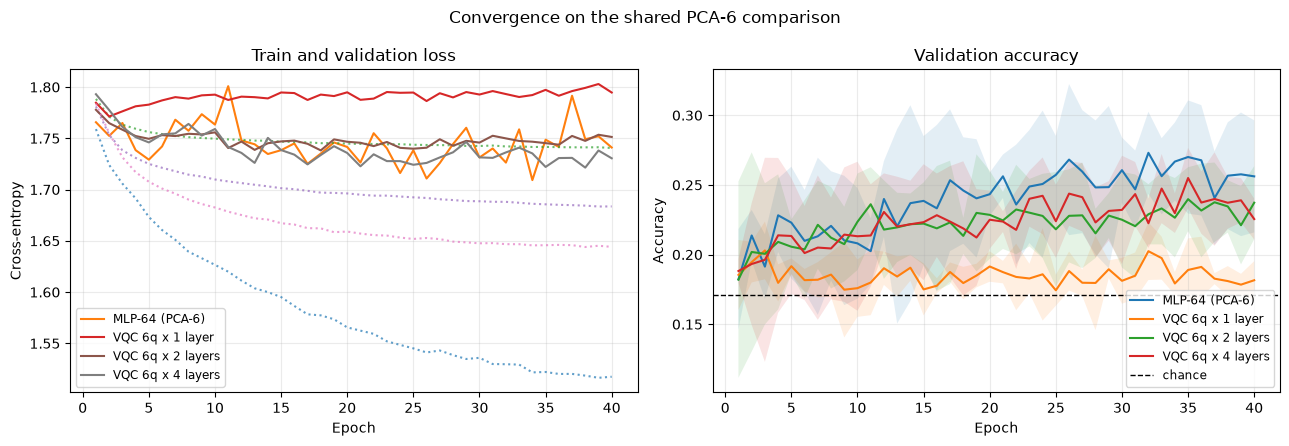

Convergence plot: dotted = training loss; solid = validation loss. Accuracy shading shows +/- one seed standard deviation.


,label,best_epoch_mean,best_val_accuracy_mean,best_val_accuracy_sd
0,MLP-64 (570 features),26.666667,0.636011,0.011562
1,MLP-64 (PCA-4),23.000000,0.254890,0.023828
2,MLP-64 (PCA-6),31.666667,0.285025,0.042349
3,MLP-64 (PCA-8),25.000000,0.329330,0.040052
4,VQC 4q x 1 layer,28.000000,0.220549,0.017304
5,VQC 4q x 2 layers,28.666667,0.224572,0.034825
6,VQC 4q x 4 layers,14.333333,0.241404,0.041955
7,VQC 6q x 1 layer,23.666667,0.213210,0.017093
8,VQC 6q x 2 layers,18.000000,0.263353,0.027069
9,VQC 6q x 4 layers,31.333333,0.259114,0.023611


In [7]:
import matplotlib.pyplot as plt


convergence_path = OUTPUT_DIR / "convergence.csv"
if not convergence_path.is_file():
    raise FileNotFoundError(f"Convergence data is missing: {convergence_path}")
convergence = pd.read_csv(convergence_path)
reference_qubits = int(config_used["report"]["reference_qubits"])
comparison = convergence[
    ((convergence["model"] == "vqc") & (convergence["n_qubits"] == reference_qubits))
    | ((convergence["model"] == "mlp_pca") & (convergence["n_qubits"] == reference_qubits))
]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
for label, runs in comparison.groupby("label"):
    epochs = runs.groupby("epoch").agg(
        train_loss=("train_loss", "mean"), val_loss=("val_loss", "mean"),
        train_acc=("train_acc", "mean"), val_acc=("val_acc", "mean"), val_acc_sd=("val_acc", "std"),
    )
    axes[0].plot(epochs.index, epochs["train_loss"], linestyle=":", alpha=0.7)
    axes[0].plot(epochs.index, epochs["val_loss"], label=label)
    axes[1].plot(epochs.index, epochs["val_acc"], label=label)
    spread = epochs["val_acc_sd"].fillna(0)
    axes[1].fill_between(epochs.index, epochs["val_acc"] - spread, epochs["val_acc"] + spread, alpha=0.12)

axes[1].axhline(chance, color="black", linestyle="--", linewidth=1, label="chance")
axes[0].set(title="Train and validation loss", xlabel="Epoch", ylabel="Cross-entropy")
axes[1].set(title="Validation accuracy", xlabel="Epoch", ylabel="Accuracy")
for axis in axes:
    axis.grid(alpha=0.25)
    axis.legend(fontsize="small")
fig.suptitle(f"Convergence on the shared PCA-{reference_qubits} comparison")
fig.tight_layout()
plt.show()
print("Convergence plot: dotted = training loss; solid = validation loss. Accuracy shading shows +/- one seed standard deviation.")

best_epochs = convergence.loc[convergence.groupby("run_id")["val_acc"].idxmax()]
display(best_epochs.groupby("label", as_index=False).agg(
    best_epoch_mean=("epoch", "mean"), best_val_accuracy_mean=("val_acc", "mean"),
    best_val_accuracy_sd=("val_acc", "std"),
))

### 3. Execution latency and circuit evaluations

The accuracy-versus-latency plot compares median single-window CPU inference time. The table reports VQC parameter count, training and test circuit evaluations, simulator batches, and the estimated parameter-shift gradient evaluation count.

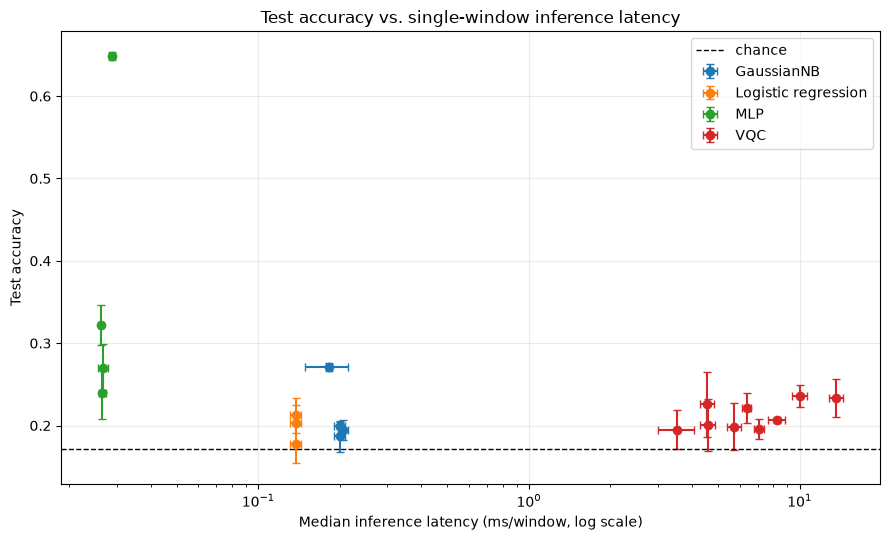

,Circuit,Quantum parameters,Training circuit evals,Training simulator batches,Parameter-shift equivalent (train),Test circuit evals,Test simulator batches
0,VQC 4q x 1 layer,12.0,374200.0,5240.0,8.161667e+06,2343.0,10.0
1,VQC 4q x 2 layers,24.0,374200.0,5240.0,1.599687e+07,2343.0,10.0
2,VQC 4q x 4 layers,48.0,374200.0,5240.0,3.166727e+07,2343.0,10.0
3,VQC 6q x 1 layer,18.0,374200.0,5240.0,1.207927e+07,2343.0,10.0
4,VQC 6q x 2 layers,36.0,374200.0,5240.0,2.383207e+07,2343.0,10.0
5,VQC 6q x 4 layers,72.0,374200.0,5240.0,4.733767e+07,2343.0,10.0
6,VQC 8q x 1 layer,24.0,374200.0,5240.0,1.599687e+07,2343.0,10.0
7,VQC 8q x 2 layers,48.0,374200.0,5240.0,3.166727e+07,2343.0,10.0
8,VQC 8q x 4 layers,96.0,374200.0,5240.0,6.300807e+07,2343.0,10.0


In [8]:
fig, ax = plt.subplots(figsize=(9, 5.5))
for family, models in summary.groupby("family"):
    ax.errorbar(
        models["latency_ms_mean"], models["accuracy_mean"],
        xerr=models["latency_ms_sd"].fillna(0), yerr=models["accuracy_sd"].fillna(0),
        fmt="o", capsize=3, label=family,
    )
ax.set_xscale("log")
ax.axhline(chance, color="black", linestyle="--", linewidth=1, label="chance")
ax.set(title="Test accuracy vs. single-window inference latency", xlabel="Median inference latency (ms/window, log scale)", ylabel="Test accuracy")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
plt.show()

quantum_counts = summary[summary["model"] == "vqc"][
    ["label", "n_quantum_parameters", "circuit_evaluations_training", "simulations_training",
     "parameter_shift_equivalent_evaluations", "circuit_evaluations_inference", "simulations_inference"]
].rename(columns={
    "label": "Circuit", "n_quantum_parameters": "Quantum parameters",
    "circuit_evaluations_training": "Training circuit evals",
    "simulations_training": "Training simulator batches",
    "parameter_shift_equivalent_evaluations": "Parameter-shift equivalent (train)",
    "circuit_evaluations_inference": "Test circuit evals",
    "simulations_inference": "Test simulator batches",
})
display(quantum_counts)

### 4. Sensitivity to simulated quantum noise

The table and plot show held-out test accuracy over depolarising probabilities, relative accuracy change from the zero-noise result, and the share of changed predictions. This is a simulator-only noise study for the noise seeds configured in `configs/default.yaml`.

,label,noise_p,accuracy,changed_predictions,mean_abs_expectation,accuracy_at_zero_noise,accuracy_delta_vs_zero_noise
0,VQC 4q x 1 layer,0.00,0.220476,0.000000,0.246411,0.220476,0.000000
1,VQC 4q x 1 layer,0.01,0.222175,0.014444,0.234590,0.220476,0.001699
2,VQC 4q x 1 layer,0.05,0.229822,0.071793,0.191565,0.220476,0.009346
3,VQC 4q x 1 layer,0.10,0.230671,0.142736,0.146535,0.220476,0.010195
4,VQC 4q x 2 layers,0.00,0.215378,0.000000,0.102354,0.215378,0.000000
5,VQC 4q x 2 layers,0.01,0.213254,0.032710,0.094855,0.215378,-0.002124
6,VQC 4q x 2 layers,0.05,0.204333,0.228547,0.069335,0.215378,-0.011045
7,VQC 4q x 2 layers,0.10,0.200510,0.528037,0.045842,0.215378,-0.014868
8,VQC 4q x 4 layers,0.00,0.200935,0.000000,0.194081,0.200935,0.000000
9,VQC 4q x 4 layers,0.01,0.203059,0.158454,0.166174,0.200935,0.002124


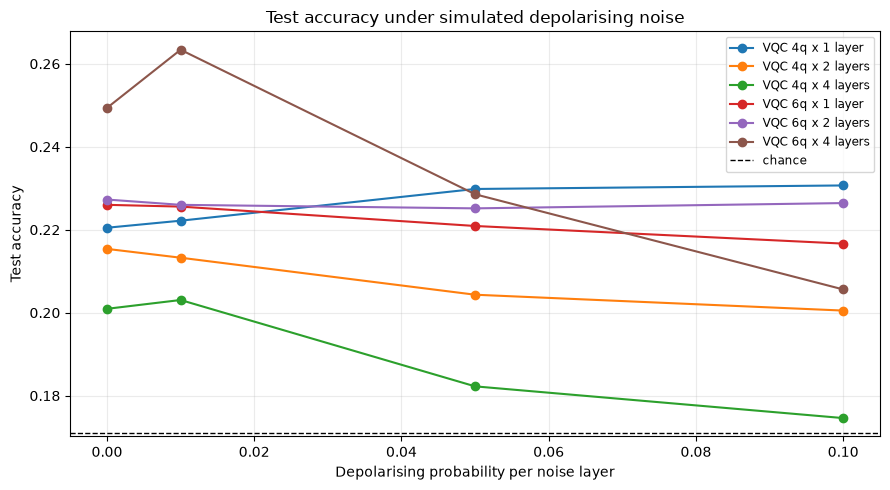

Noise results are simulator-only and use the configured noise seed(s).
Detailed report: /home/prasndhdl/Downloads/avatar/Tellekynezix/prediction-quantum/BENCHMARK.md


In [9]:
noise_path = OUTPUT_DIR / "noise_sweep.csv"
if not noise_path.is_file():
    print("No noise sweep was generated for this configuration.")
else:
    noise = pd.read_csv(noise_path)
    if noise.empty:
        print("Noise-sweep output is empty for this configuration.")
    else:
        noise_summary = noise.groupby(["label", "noise_p"], as_index=False).agg(
            accuracy=("accuracy", "mean"), changed_predictions=("changed_predictions", "mean"),
            mean_abs_expectation=("mean_abs_expectation", "mean"),
        )
        baseline = noise_summary.loc[noise_summary["noise_p"] == noise_summary["noise_p"].min(), ["label", "accuracy"]]
        baseline = baseline.rename(columns={"accuracy": "accuracy_at_zero_noise"})
        noise_summary = noise_summary.merge(baseline, on="label", validate="many_to_one")
        noise_summary["accuracy_delta_vs_zero_noise"] = noise_summary["accuracy"] - noise_summary["accuracy_at_zero_noise"]
        display(noise_summary)

        fig, ax = plt.subplots(figsize=(9, 5))
        for label, circuit in noise_summary.groupby("label"):
            circuit = circuit.sort_values("noise_p")
            ax.plot(circuit["noise_p"], circuit["accuracy"], marker="o", label=label)
        ax.axhline(chance, color="black", linestyle="--", linewidth=1, label="chance")
        ax.set(title="Test accuracy under simulated depolarising noise", xlabel="Depolarising probability per noise layer", ylabel="Test accuracy")
        ax.grid(alpha=0.25)
        ax.legend(fontsize="small")
        fig.tight_layout()
        plt.show()
        print("Noise results are simulator-only and use the configured noise seed(s).")

print(f"Detailed report: {REPORT_PATH}")